Live trainning monitor

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import time

from IPython.display import clear_output, display

def plot_live_training(csv_file="training_history.csv"):

    while True:
        try:
            # Read latest training results
            history = pd.read_csv(csv_file)

            if history.empty:
                time.sleep(2)
                continue

            # Update plots
            clear_output(wait=True)

            fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

            epochs = range(1, len(history) + 1)

            # Training and validation loss
            ax1.plot(epochs, history['train_loss'], label='train')
            ax1.plot(epochs, history['val_loss'], label='val')

            ax1.set_xlabel('Epoch')
            ax1.set_ylabel('Loss')
            ax1.set_title('Training and Validation Loss')
            ax1.legend()
            ax1.grid(True)

            # Validation error
            ax2.plot(epochs, history['val_error'], color='tab:orange')

            ax2.set_xlabel('Epoch')
            ax2.set_ylabel('Error rate')
            ax2.set_title('Validation Error')
            ax2.grid(True)

            plt.tight_layout()

            display(fig)
            plt.close(fig)

            print(f"Completed epochs: {len(history)}")
            print(f"Training loss: {history['train_loss'].iloc[-1]:.4f}")
            print(f"Validation loss: {history['val_loss'].iloc[-1]:.4f}")
            print(f"Validation accuracy: {(1-history['val_error'].iloc[-1])*100:.2f}%")

        except (FileNotFoundError, pd.errors.EmptyDataError):
            print("Waiting for training data...")

        # Refresh every 5 seconds
        time.sleep(5)

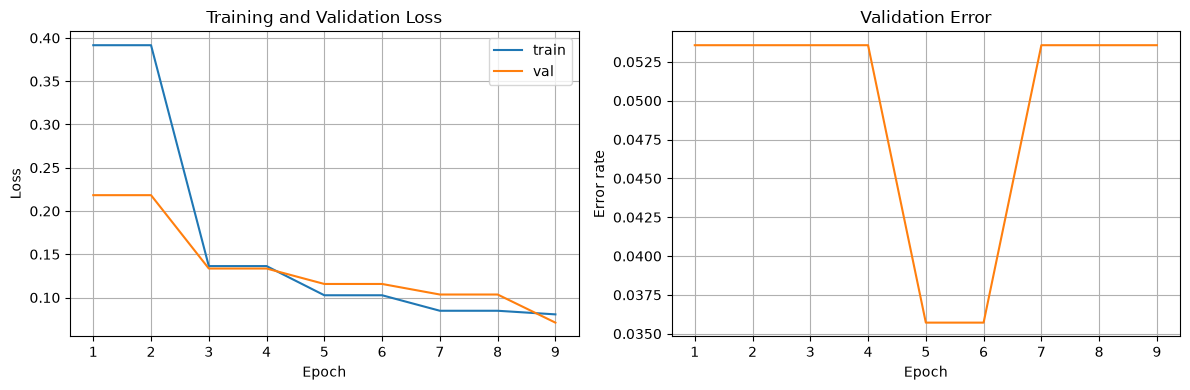

Completed epochs: 9
Training loss: 0.0805
Validation loss: 0.0710
Validation accuracy: 94.64%


KeyboardInterrupt: 

In [7]:
plot_live_training()